In [22]:
from keras.datasets import cifar10
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

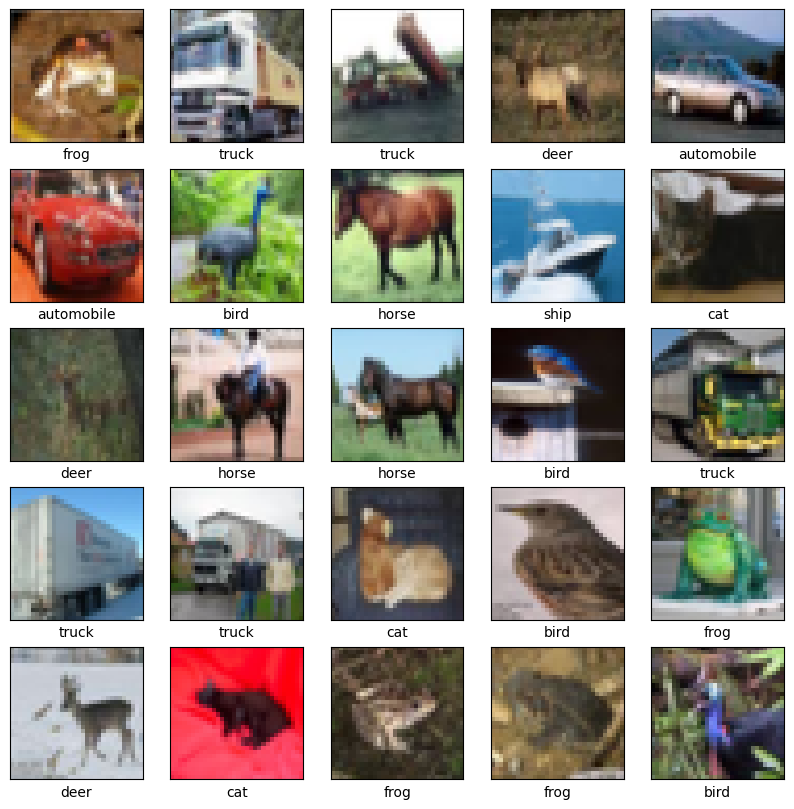

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.xlabel(class_names[train_labels[i][0]])
    plt.imshow(x_train[i])

plt.show()

In [24]:
train_images = train_images.reshape((50000, 32 * 32 * 3))
train_images = train_images.astype('float32') / 255
test_images = test_images.reshape((10000, 32 * 32 * 3))
test_images = test_images.astype('float32') / 255

In [25]:
from keras.utils import to_categorical
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

In [26]:
from keras import models 
from keras import layers

network = models.Sequential()
network.add(layers.Dense(512, activation = 'relu', input_shape=(32 * 32 * 3,)))
network.add(layers.Dense(10, activation = 'softmax'))

In [27]:
network.compile(
    optimizer='rmsprop',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
network.fit(
    train_images,
    train_labels,
    epochs=50,
    batch_size=128
)

In [29]:
test_loss, test_acc = network.evaluate(
    test_images,
    test_labels
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4536 - loss: 1.5543


In [30]:
network.save('model_cifar.keras')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


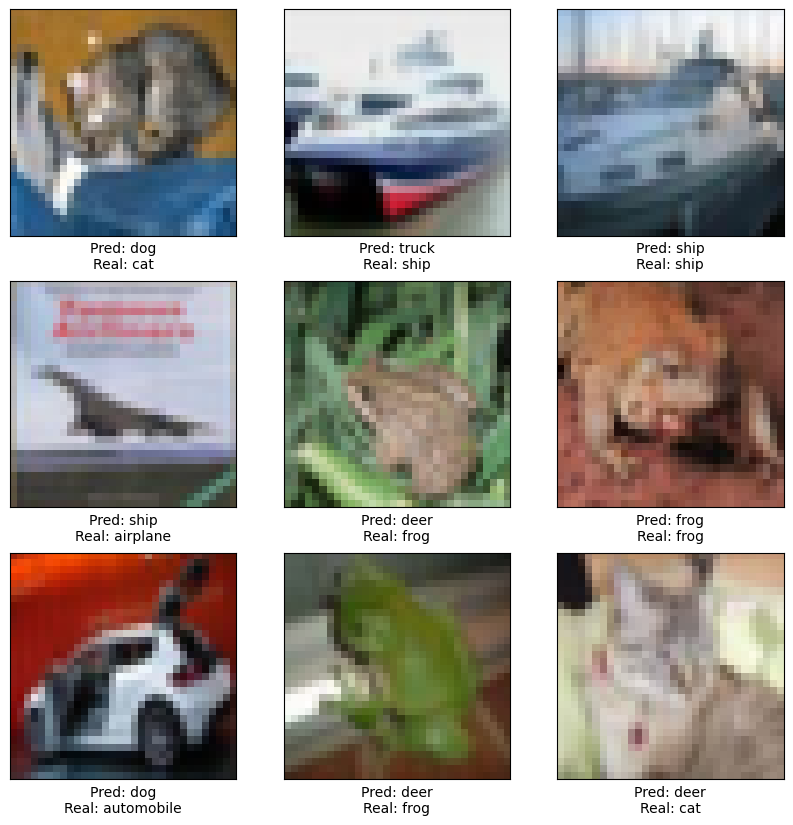

In [31]:
import numpy as np

predictions = network.predict(test_images)

plt.figure(figsize=(10,10))

for i in range(9):

    plt.subplot(3,3,i+1)

    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    plt.imshow(
        test_images[i].reshape(32,32,3)
    )

    predicted_label = np.argmax(predictions[i])
    true_label = np.argmax(test_labels[i])

    plt.xlabel(
        "Pred: " + class_names[predicted_label] +
        "\nReal: " + class_names[true_label]
    )

plt.show()